In [1]:
import torch
from datasets import Dataset
from modelscope import snapshot_download, AutoTokenizer
from swanlab.integration.transformers import SwanLabCallback
from qwen_vl_utils import process_vision_info
from peft import LoraConfig, TaskType, get_peft_model, PeftModel
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorForSeq2Seq,
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
)
import swanlab
import json
import os

In [2]:
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "./Qwen2.5-VL-3B-Instruct", torch_dtype="auto", device_map="auto"
)
processor = AutoProcessor.from_pretrained("./Qwen2.5-VL-3B-Instruct")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.
You have video processor config saved in `preprocessor.json` file which is deprecated. Video processor configs should be saved in their own `video_preprocessor.json` file. You can rename the file or load and save the processor back which renames it automatically. Loading from `preprocessor.json` will be removed in v5.0.


In [3]:
model

Qwen2_5_VLForConditionalGeneration(
  (model): Qwen2_5_VLModel(
    (visual): Qwen2_5_VisionTransformerPretrainedModel(
      (patch_embed): Qwen2_5_VisionPatchEmbed(
        (proj): Conv3d(3, 1280, kernel_size=(2, 14, 14), stride=(2, 14, 14), bias=False)
      )
      (rotary_pos_emb): Qwen2_5_VisionRotaryEmbedding()
      (blocks): ModuleList(
        (0-31): 32 x Qwen2_5_VLVisionBlock(
          (norm1): Qwen2RMSNorm((1280,), eps=1e-06)
          (norm2): Qwen2RMSNorm((1280,), eps=1e-06)
          (attn): Qwen2_5_VLVisionAttention(
            (qkv): Linear(in_features=1280, out_features=3840, bias=True)
            (proj): Linear(in_features=1280, out_features=1280, bias=True)
          )
          (mlp): Qwen2_5_VLMLP(
            (gate_proj): Linear(in_features=1280, out_features=3420, bias=True)
            (up_proj): Linear(in_features=1280, out_features=3420, bias=True)
            (down_proj): Linear(in_features=3420, out_features=1280, bias=True)
            (act_fn): SiLU()

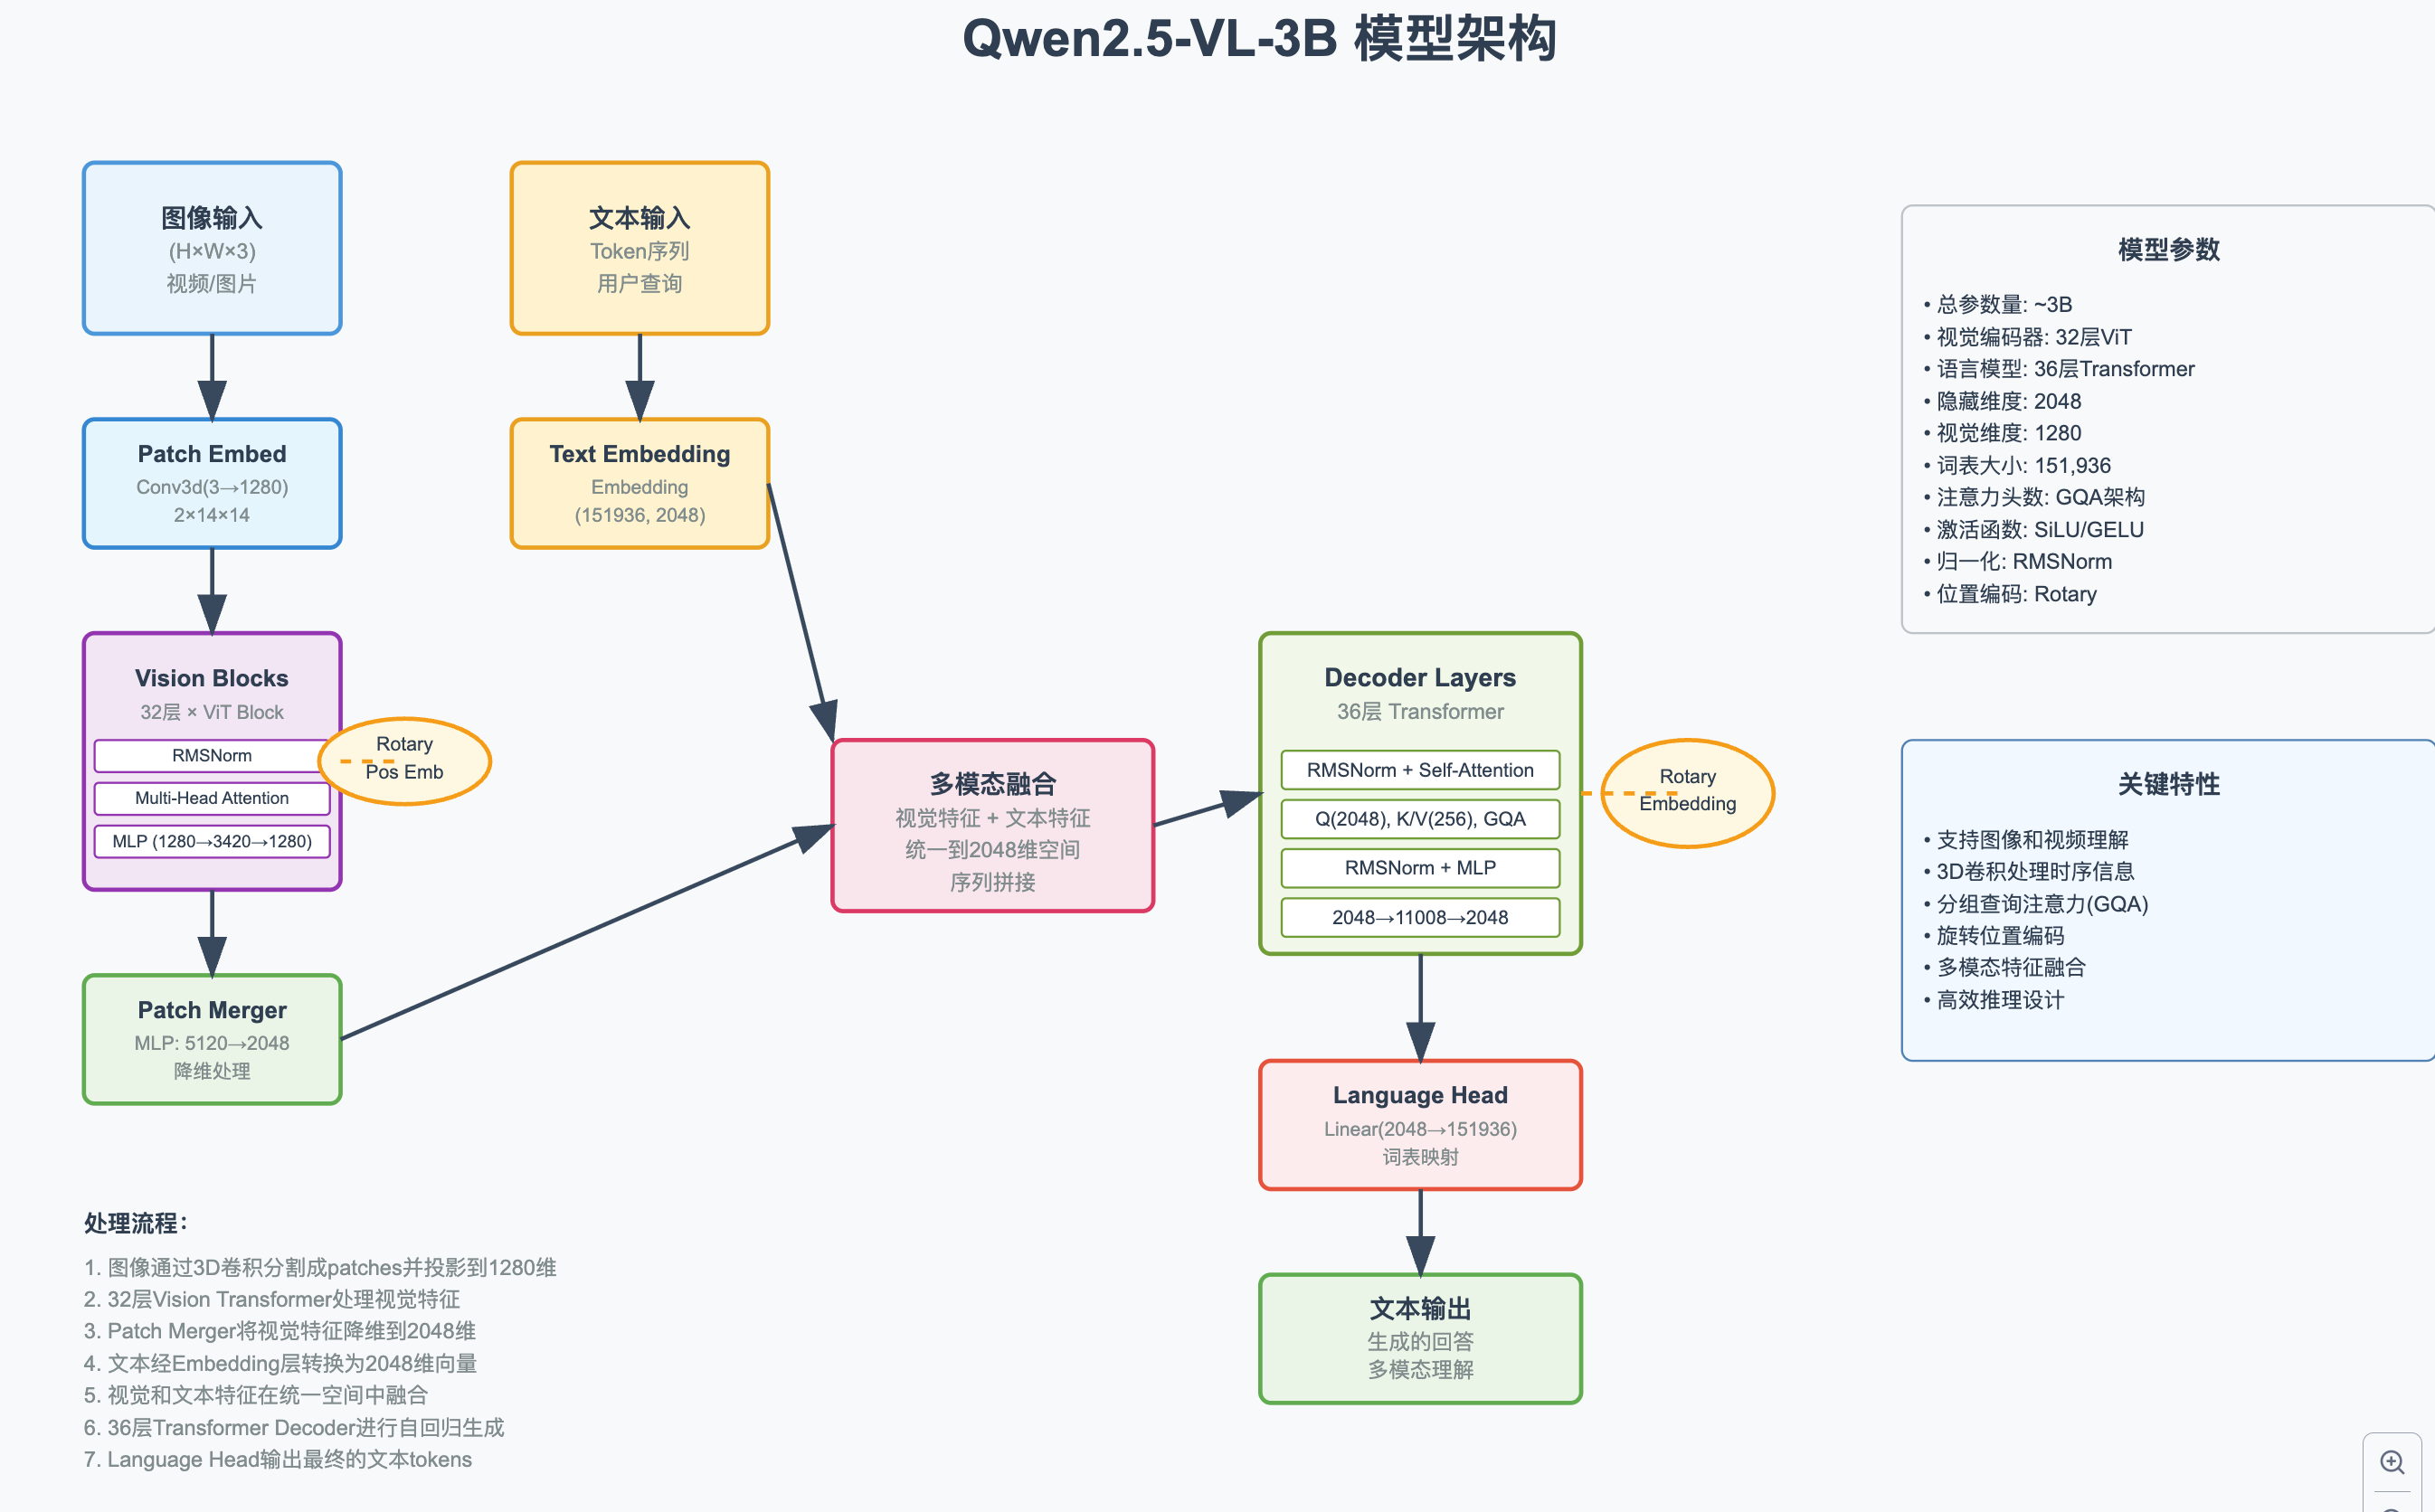

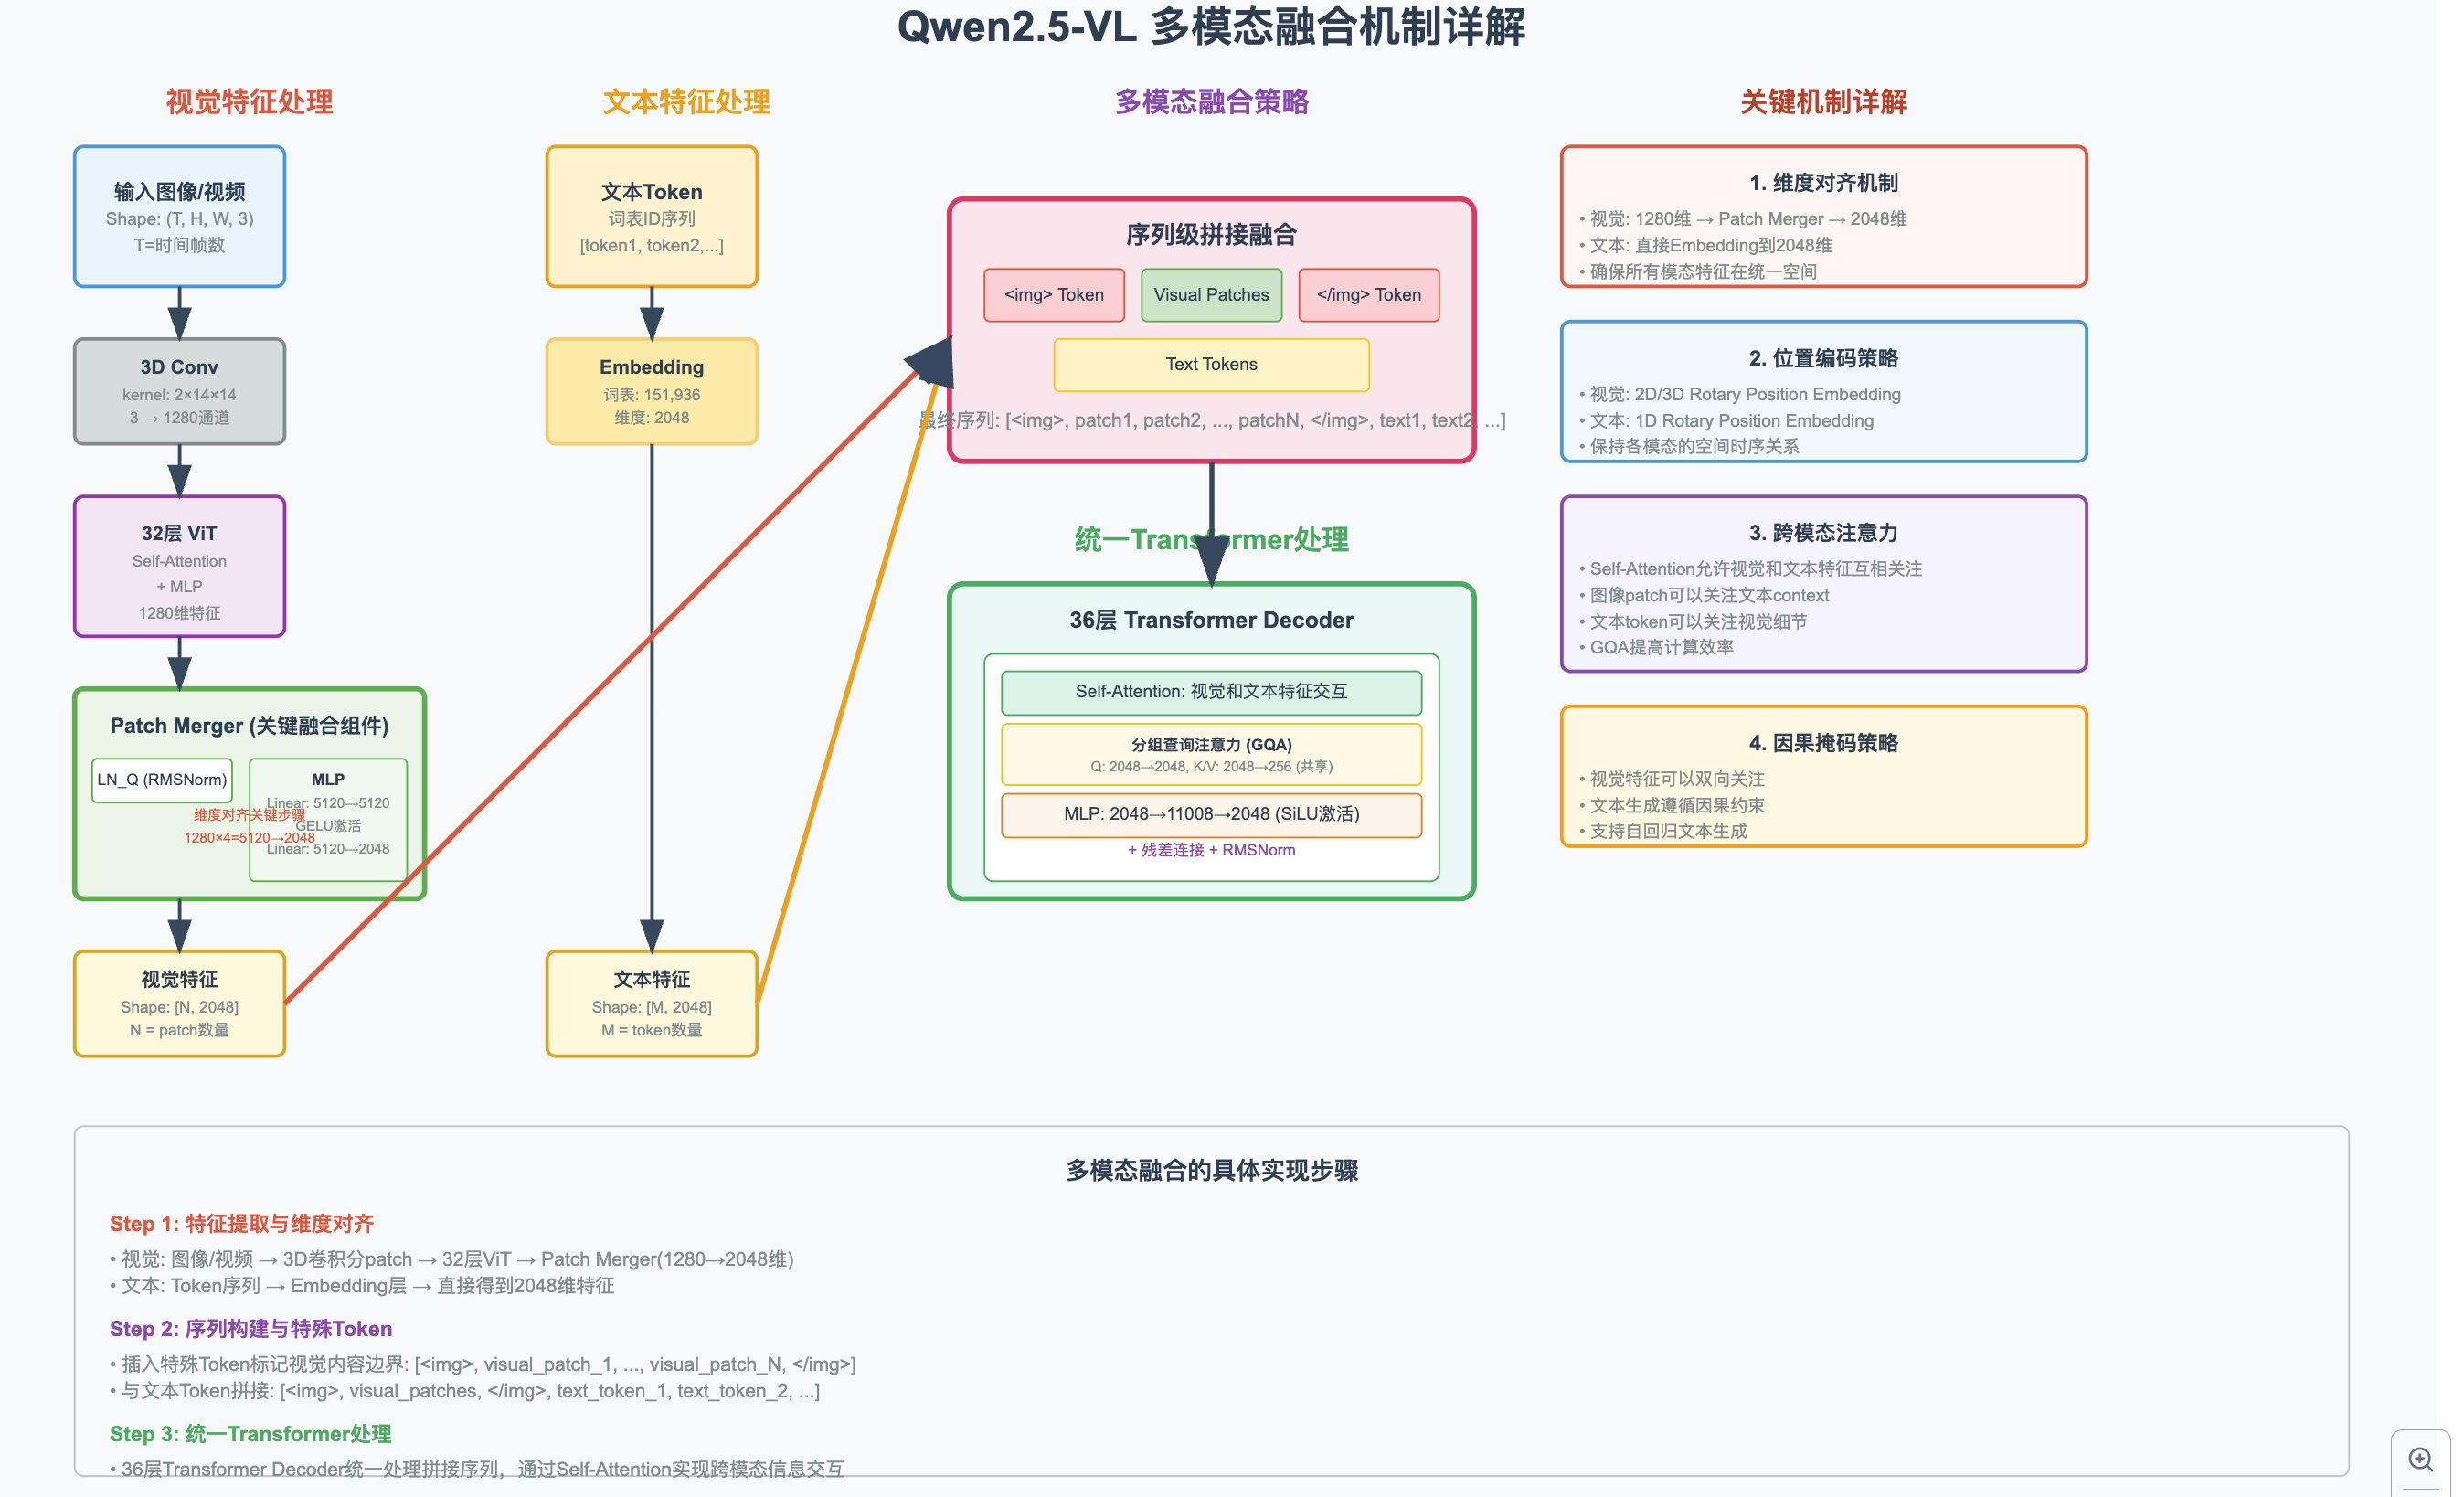

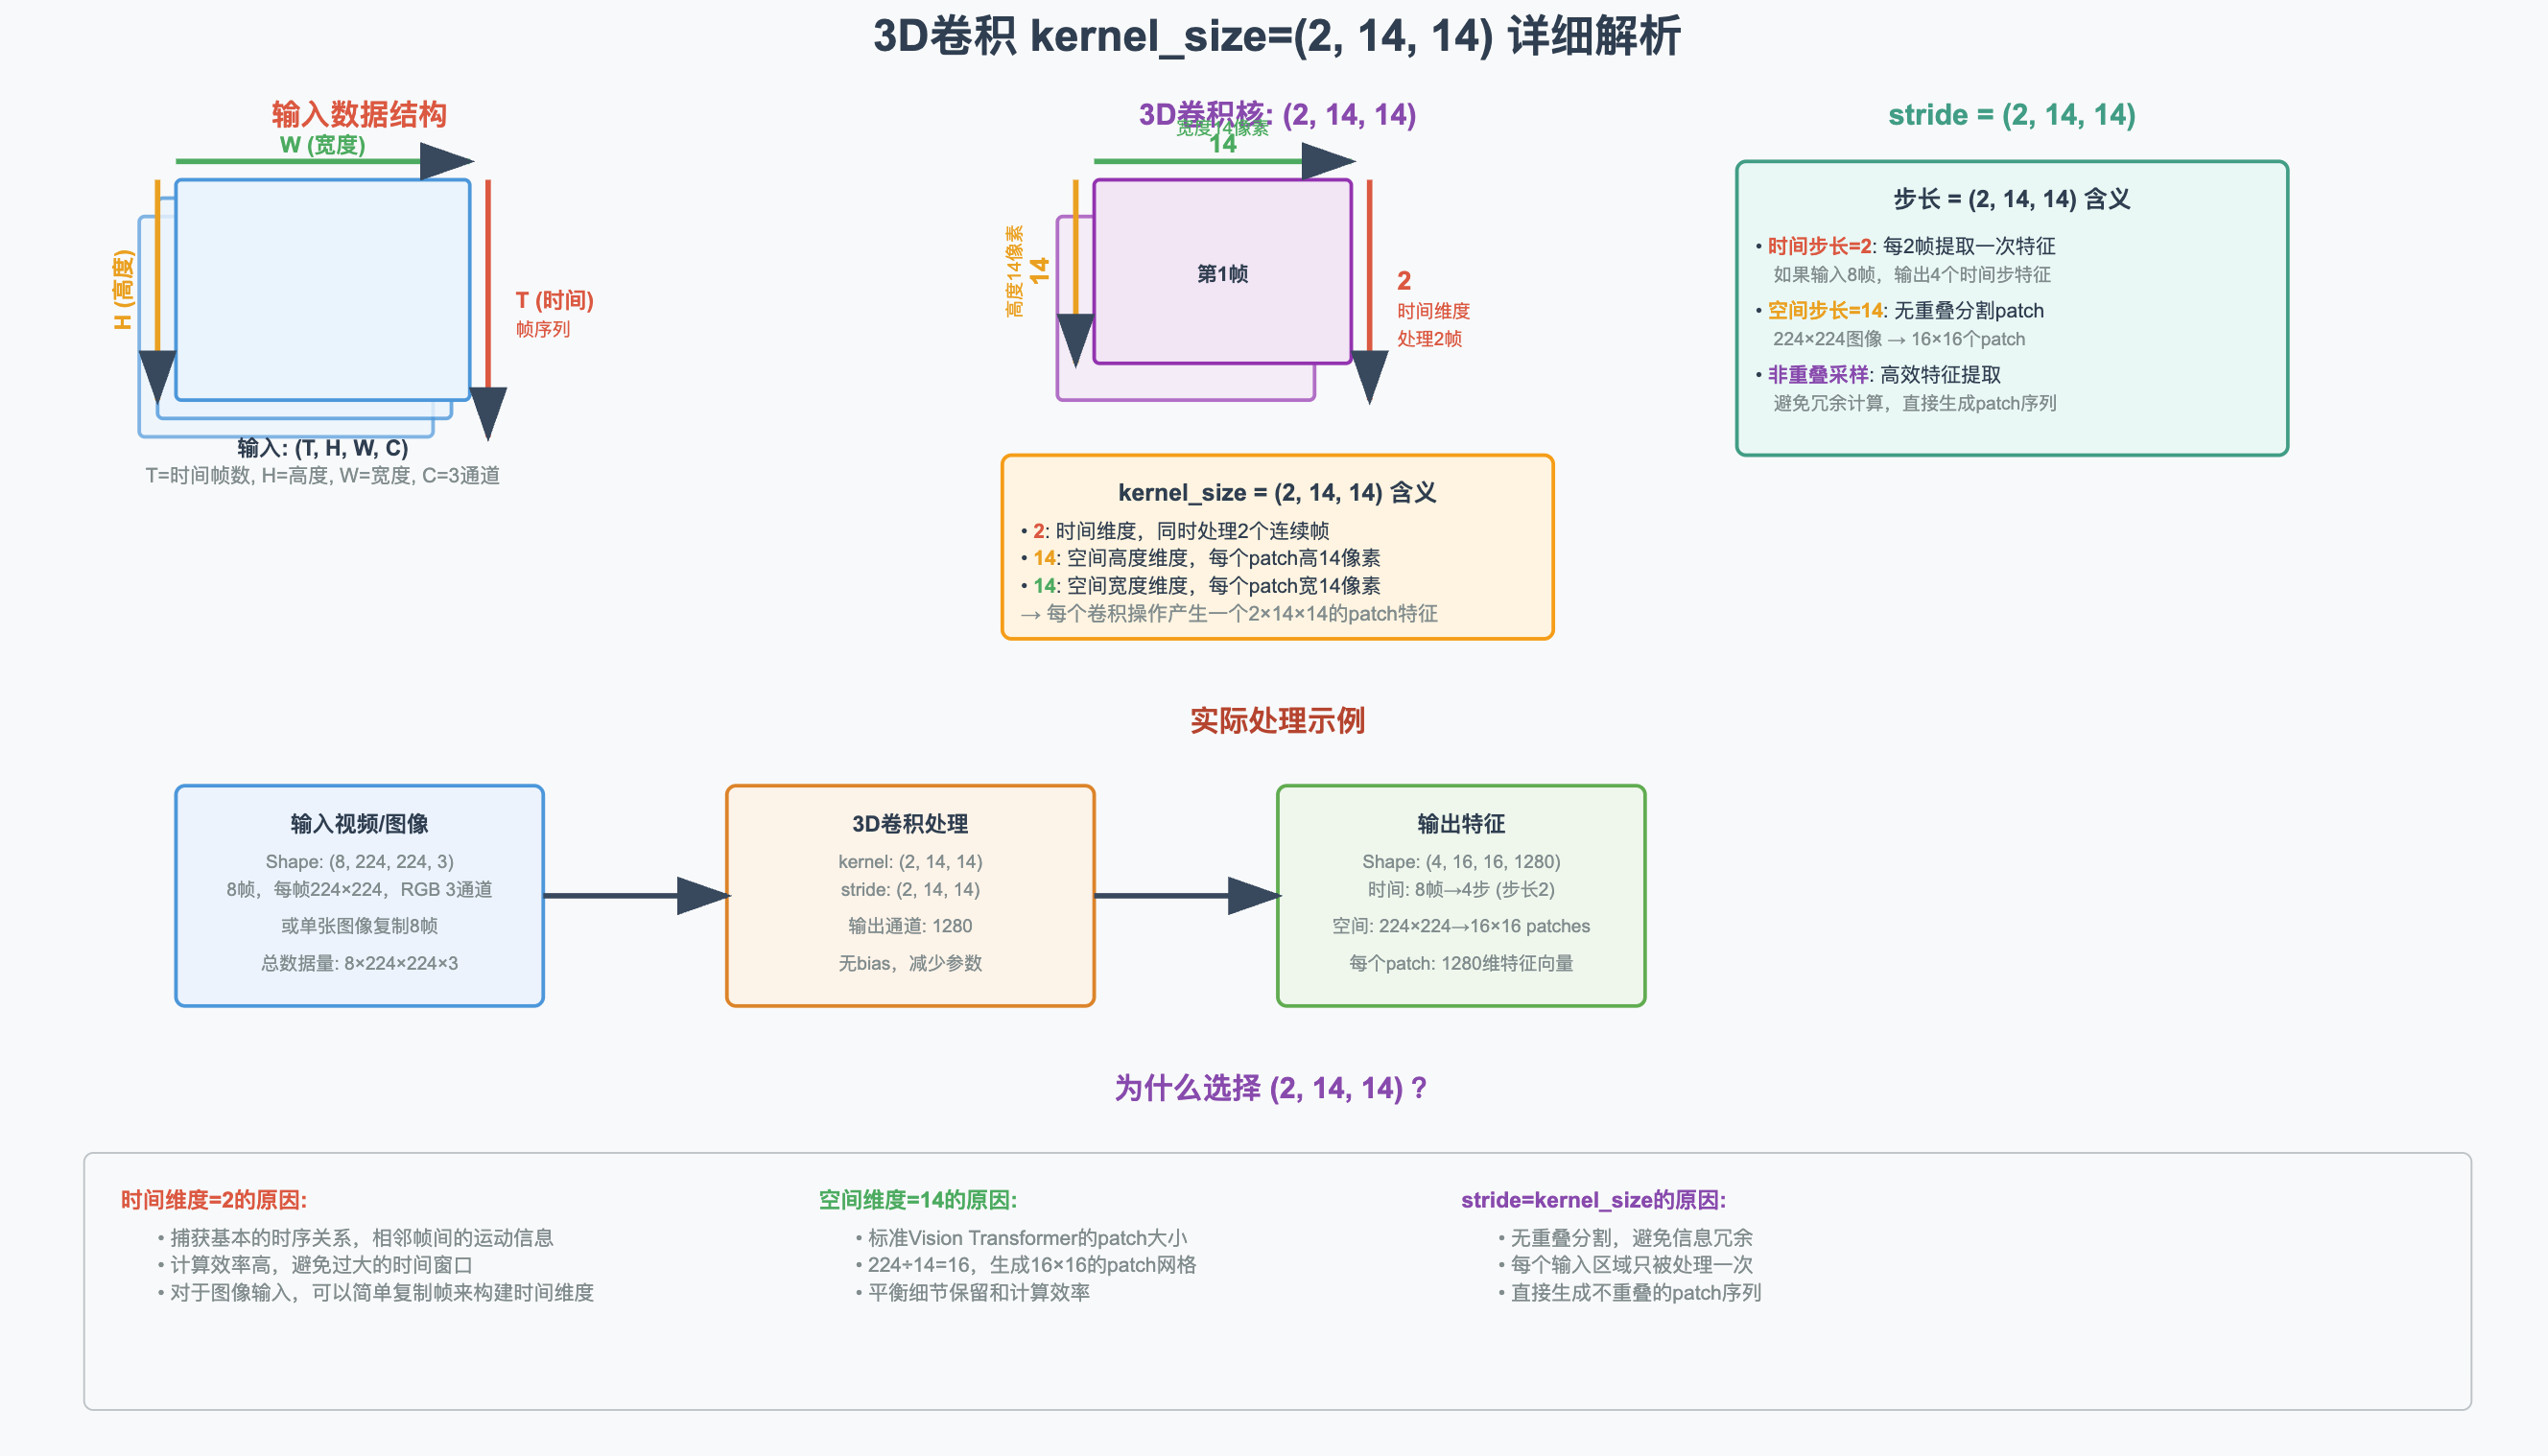

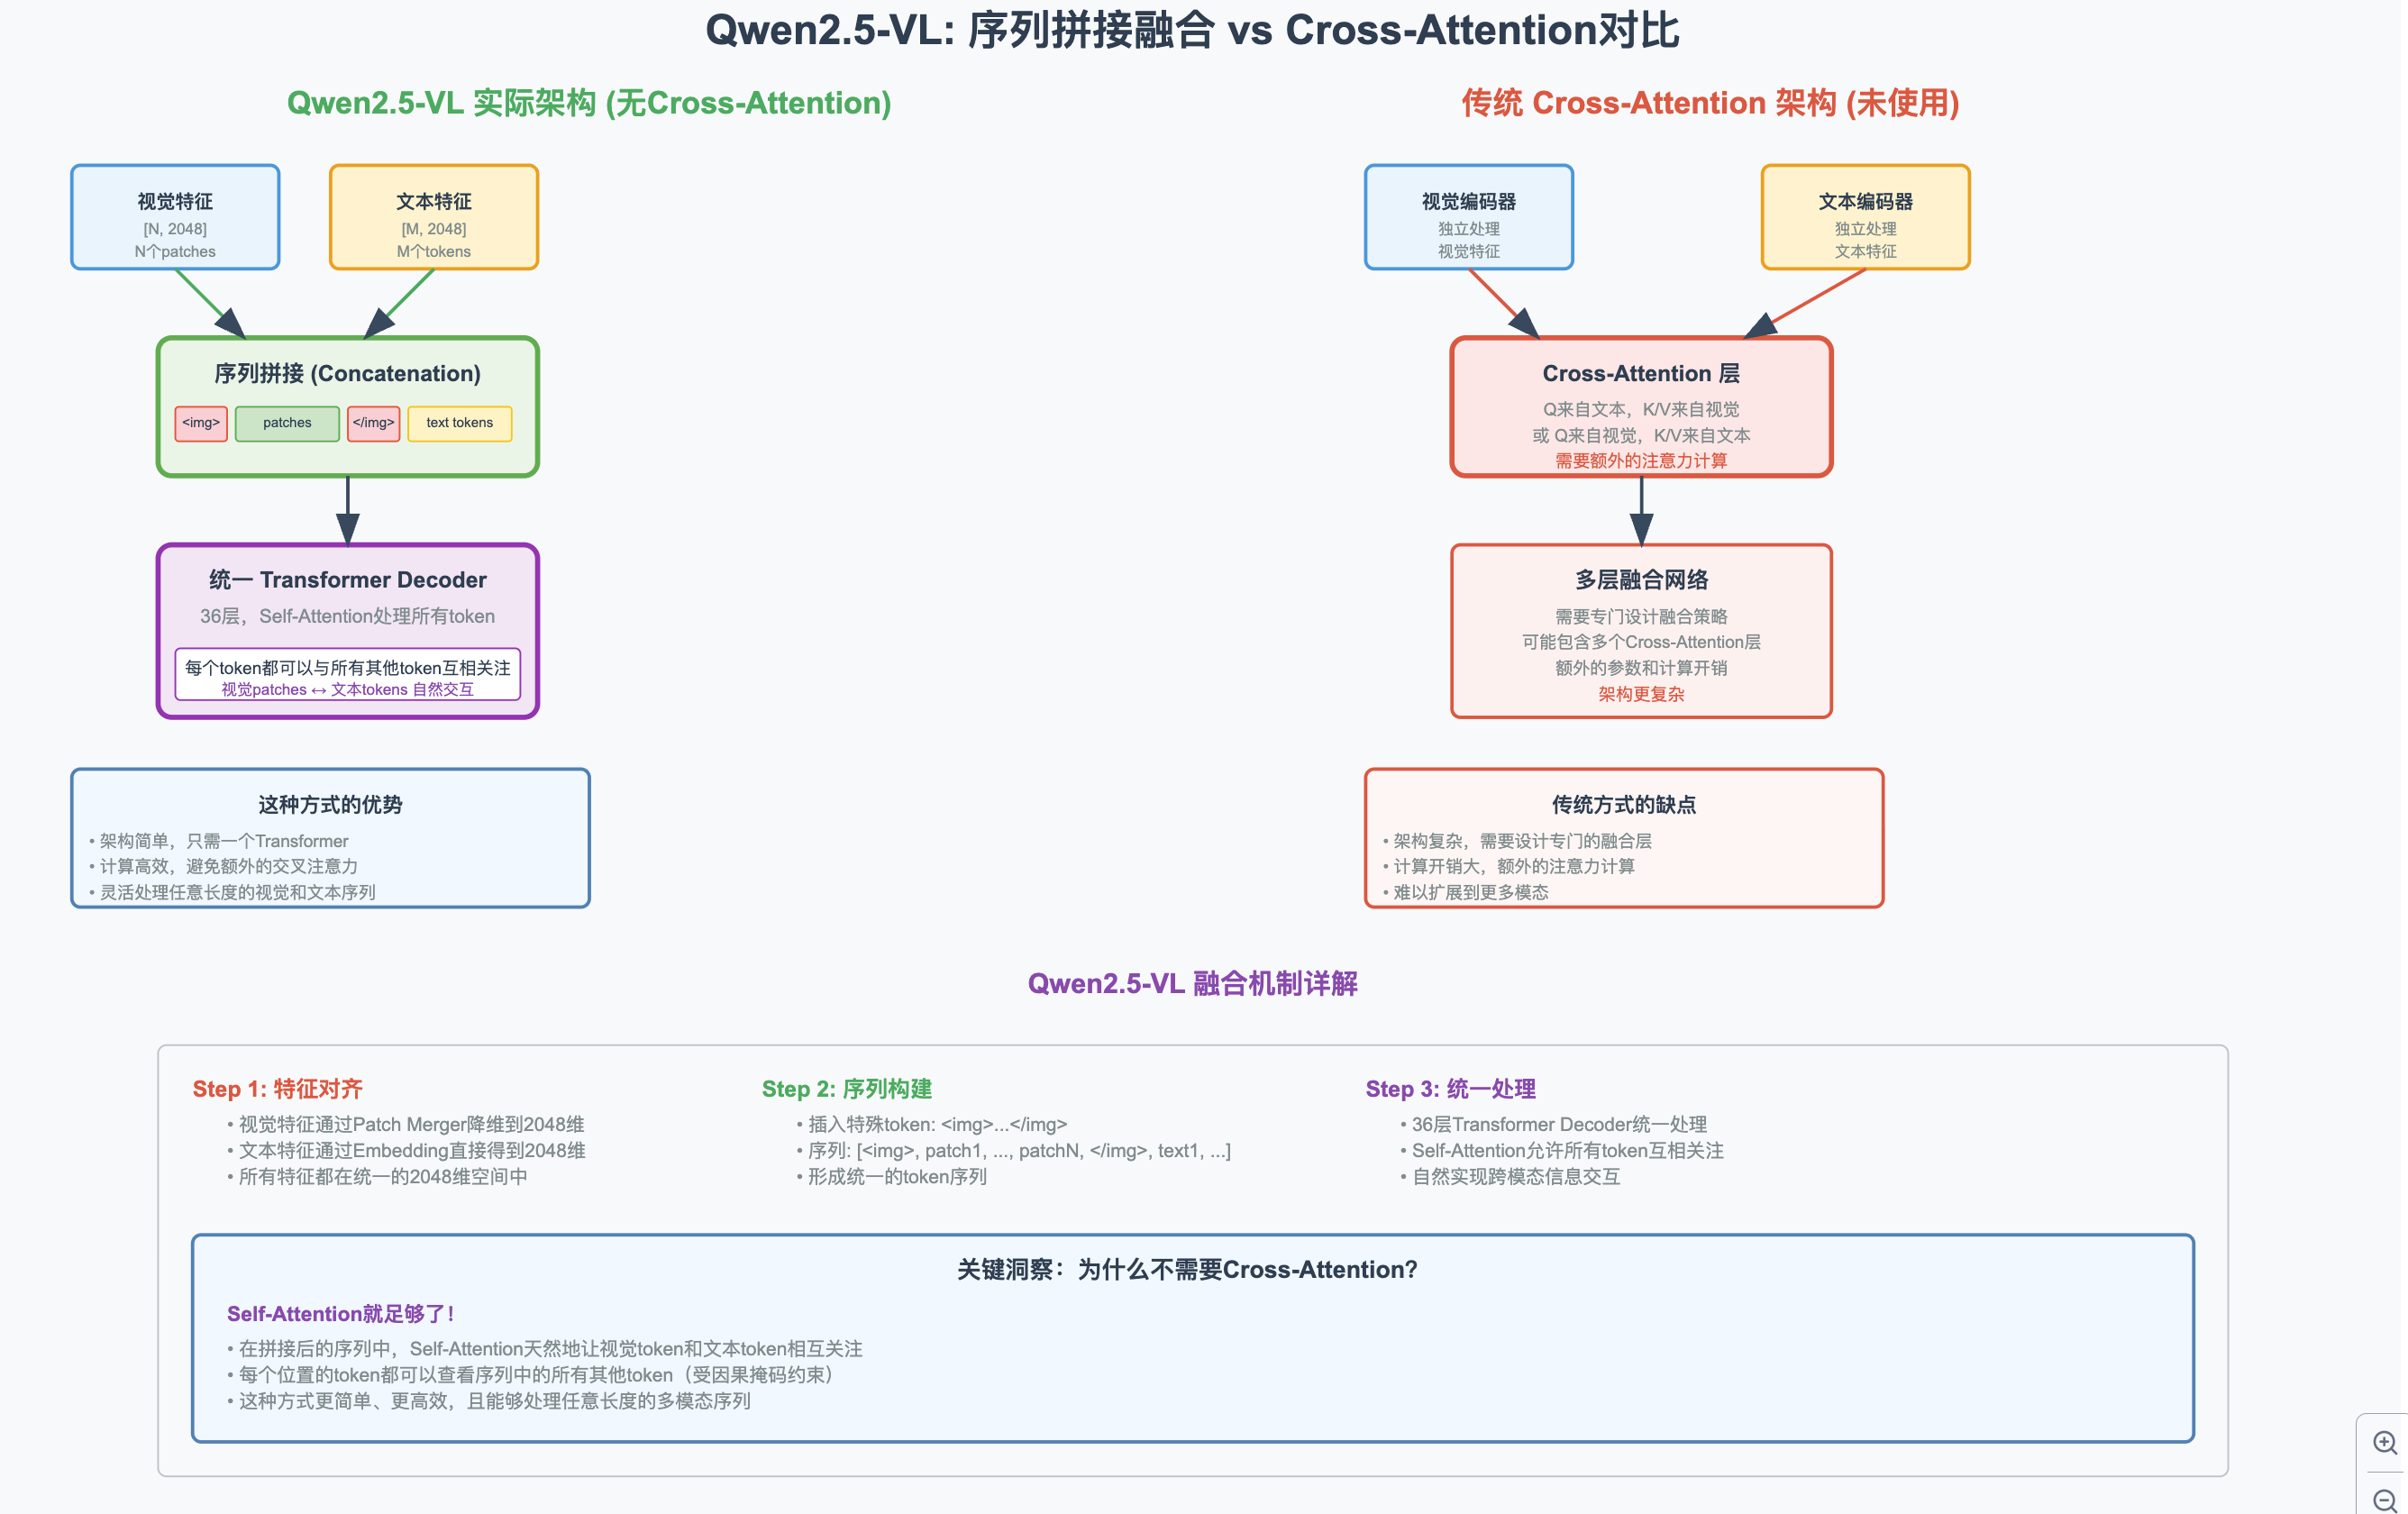

下面按“从外到内”的顺序，把你贴出的 **Qwen2.5‑VL‑3B** 的 `nn.Module` 结构逐块解释清楚，并给出它们在训练/推理中的作用、典型张量形状变化与背后的设计动机。

---

## 0) 最外层封装

### `Qwen2_5_VLForConditionalGeneration`

* **作用**：生成式封装（“for conditional generation”），把视觉编码器和文本解码器组合起来，提供类似 `generate` 的推理接口（采样、束搜索、缓存 KV、停止词等）。
* **组成**：它持有一个 `Qwen2_5_VLModel`（真正的多模态骨干）以及最后的 `lm_head`（词表投影）。

---

## 1) 多模态骨干

### `Qwen2_5_VLModel`

* **作用**：多模态主干，包含两个子塔：

  * `visual`：视觉编码器，把图像/视频转成**视觉token序列**。
  * `language_model`：纯解码式语言模型，把（视觉token + 文本token）作为输入，做自回归生成。
* **典型数据流**：

  1. 图像/视频 → 视觉塔 → 视觉token（在此模型中最终会被对齐到 2048 维）。
  2. 文本 → 词嵌入（2048 维）。
  3. 把视觉token作为“前缀token”与文本token拼接，输入到解码器层堆叠中进行生成。

---

## 2) 视觉塔（Vision Transformer）

### `Qwen2_5_VisionTransformerPretrainedModel`

由以下模块构成：

#### 2.1 `Qwen2_5_VisionPatchEmbed`

```
(proj): Conv3d(3, 1280, kernel_size=(2, 14, 14), stride=(2, 14, 14), bias=False)
```

* **作用**：**补丁化（patchify）+ 线性映射**。把输入的 RGB 帧序列切成不重叠的时空小块，并把每个小块映射到 **1280维** 的视觉嵌入。
* **为什么是 Conv3d**：核大小 `(2,14,14)`、步幅 `(2,14,14)` 表明它同时在\*\*时间维（2帧）**和**空间维（14×14 像素）\*\*上做分块。这使同一模型可以同时处理图片（可视作特殊的“短视频”）与视频输入。
* **Token 数量**：若输入为 `T×H×W`，且都能整除，则

  $$
  N_{\text{tokens}}=\frac{T}{2}\times\frac{H}{14}\times\frac{W}{14}.
  $$

  例如 `T=2, H=W=224`，则得到 `1×16×16=256` 个视觉token。
* **注意**：对于单帧图像，具体实现常见做法有两种（此处不强行断言实际采用哪种）：

  1. 在前处理将图片在时间维度扩展/复制到 `T=2`；
  2. 在实现中分支处理单帧情形（等效于 2D patchify）。

#### 2.2 `Qwen2_5_VisionRotaryEmbedding`

* **作用**：给视觉token引入**旋转位置编码（RoPE）**。RoPE把位置信息以可旋转的方式注入到注意力的 Q/K 向量里，一般能更好处理长序列与插值到未见过的分辨率/时长。
* **视觉RoPE** 通常会考虑二维（高/宽）甚至带上时间维的相对位置信息。

#### 2.3 `blocks: 32 × Qwen2_5_VLVisionBlock`

每个视觉块包含：

* `norm1` / `norm2`: **RMSNorm**（均方根归一化，`eps=1e-6`，数值更稳定）。
* `attn: Qwen2_5_VLVisionAttention`

  * `qkv: Linear(1280→3840)`：把输入 token 的 1280 维特征投到 `Q,K,V`，合在一个线性层里（`3840=3×1280`）。
  * `proj: Linear(1280→1280)`：多头注意力聚合后的输出映射回 1280 维。
  * **多头/GQA**：视觉部分 `qkv` 同维，通常是**标准多头注意力**（未显式显示 GQA 迹象）。
* `mlp: Qwen2_5_VLMLP`

  * `gate_proj / up_proj: 1280→3420`、`down_proj: 3420→1280`、激活 `SiLU`。
  * **含门控的前馈网络（GLU风格）**：用 `gate_proj` 与 `up_proj` 双分支结合非线性后再 `down_proj` 回到隐藏维。`3420/1280≈2.67` 是视觉塔的扩展倍率（小于文本塔的扩展倍率，见 §3）。
* **残差与前归一化**：每个 block 一般是 “RMSNorm → 注意力 → 残差加”和 “RMSNorm → MLP → 残差加”。

#### 2.4 `merger: Qwen2_5_VLPatchMerger`

```
(ln_q): Qwen2RMSNorm((1280,), eps=1e-06)
(mlp): Linear(5120→5120) → GELU → Linear(5120→2048)
```

* **作用（关键）**：对视觉 token 做**聚合/降采样并跨模态对齐**，把**视觉隐藏维从 1280 投到 2048**，与文本塔的隐藏维对齐，便于后续把视觉token直接拼到文本序列中统一建模。
* **为什么是 5120 输入**：`5120 = 4 × 1280`，暗示该合并器可能**把若干相邻/分组的视觉token特征拼接**后，再用 MLP 压缩到文本维（2048）。具体“如何分组/选取”依赖实现（例如固定分组、基于学习的选取等），从结构名“PatchMerger”可知它的目标是**减少 token 数**和**完成模态对齐**。

> 小结：视觉塔整体是一个**时空patch化 + ViT堆叠 + Token合并/对齐**的编码器，输出 token 的维度已经变成 2048，以便和文本塔对接。

---

## 3) 文本塔（Decoder‑only LLM）

### `Qwen2_5_VLTextModel`

* **嵌入层**：`Embedding(151936, 2048)`

  * 词表大小 **151,936**（多语种/大词表），嵌入维 **2048**。
  * **是否与 `lm_head` 权重共享（tie weights）** 取决于训练/配置，这里结构未明示。
* **层堆叠**：`36 × Qwen2_5_VLDecoderLayer`

  * **自注意力 `Qwen2_5_VLAttention`（带 RoPE）**

    * `q_proj: 2048→2048`
    * `k_proj: 2048→256`
    * `v_proj: 2048→256`
    * `o_proj: 2048→2048`（`bias=False`）
    * **含义**：`K/V` 只有 256 维，而 `Q` 是 2048 维，这是一种**GQA（Grouped‑Query Attention，多查询注意力）/MHA 变体**——**查询头很多，但 K/V 头更少**，从而显著降低注意力的缓存与计算开销（KV 缓存体积与 `n_kv_heads` 成正比），同时尽量保持表达能力。
    * **RoPE**：`rotary_emb` 为文本序列提供相对位置信息，利于外推长上下文。
  * **前馈 `Qwen2MLP`（门控）**

    * `gate_proj / up_proj: 2048→11008（bias=False）`，`down_proj: 11008→2048（bias=False）`，`SiLU` 激活。
    * 扩展倍率 `11008/2048≈5.375`，比视觉塔更大，这是现代 LLM 中常见的“宽 MLP”设计，提升非线性表达能力。
  * **归一化**：`input_layernorm` 与 `post_attention_layernorm` 都是 RMSNorm（`eps=1e-6`）。通常是**Pre‑Norm**架构：Norm → Attention → 残差；Norm → MLP → 残差。
* **最终归一化**：`norm: Qwen2RMSNorm((2048,), eps=1e-06)`，在喂给 `lm_head` 之前再做一次整体归一化，提升数值稳定性。

### `lm_head: Linear(2048→151936, bias=False)`

* **作用**：把隐藏状态映射到词表 logits，用于下一个 token 的概率分布。
* **bias=False**：常见于与嵌入权重共享的设置（再次提醒：是否真正共享需看配置/权重；结构本身不强制）。

---

## 4) 端到端推理流程（直观版）

1. **视觉输入**（图像或视频）经 `Conv3d` patchify 成时空补丁 → 线性化为 token 序列（每个 token 初始是 1280 维）。
2. **视觉Transformer** 堆叠（32层）对这些 token 做全局建模（自注意力+MLP）。
3. **PatchMerger** 对视觉 token **聚合/降采样**，并把维度从 1280 **投到 2048**（与文本塔对齐）。
4. **文本输入**（提示词等）通过词嵌入得到 2048 维文本 token。
5. **拼接**：把视觉 token 作为前缀（或夹在特殊占位符之后），与文本 token 形成一个统一序列（维度一致：2048）。
6. \*\*解码器（36层）\*\*以自回归方式生成下一个 token（包含 GQA 以节省 KV 开销），`lm_head` 给出词表分布。
7. 重复第 6 步完成生成。

---

## 5) 关键超参与设计取舍

* **视觉隐藏维**：1280；**文本隐藏维**：2048。
* **层数**：视觉 32 层、文本 36 层。
* **视觉 MLP 扩展**：1280→3420（≈2.67×）；**文本 MLP 扩展**：2048→11008（≈5.38×）。
* **归一化**：全程 RMSNorm、`eps=1e-6`，有助于稳定、速度和低精度训练/推理。
* **GQA（文本注意力）**：`Q:2048` 对 `K/V:256`，**减少 KV 缓存大小与算量**，利于长上下文与推理吞吐。
* **视觉合并器**：通过把若干 1280 维 token 拼成 5120 维，再 MLP 压到 2048 维，实现**跨模态维度对齐 + token 压缩**（降低后续解码器的序列长度负担）。
* **无显式跨注意力**：从结构看，视觉→文本是\*\*“早期拼接/前缀融合”\*\*，不是单独的跨注意力桥（如 BLIP‑2/Flamingo 的 Q‑Former）。这简化了系统并充分利用解码器的自注意力来建模图文交互。

---

## 6) 常见问题与补充说明

* **为什么视觉端也用 RoPE？**
  RoPE 在 2D/3D（含时间维）上表现良好，便于插值与外推，且与注意力天然兼容。
* **为什么文本端 K/V 远小于 Q？**
  这是 GQA/多查询注意力的思路：保留丰富的查询头数（表达力）同时减少 K/V 头（存储和计算热点），对推理更友好。
* **`lm_head` 是否与 `embed_tokens` 权重共享？**
  许多 LLM 会“tie weights”，但是否共享取决于配置/实现；这里的结构不直接表态。



# 如果图像不是224*-224，而是比如256*-192怎么办呢

可以用——但需要注意 **patch 大小/步幅是 14×14**（且没有 padding）。这意味着**输入的长和宽如果不是 14 的整数倍**，最右边/最下边会被卷积“走不满”，从而**被丢掉**。可以按下面几种方式处理。

---

## 1) 直接喂 256×192 会发生什么？

视觉补丁化用的是 `Conv3d(k=(2,14,14), s=(2,14,14), padding=0)`。对空间维来说，输出网格大小是：

$$
H_{\text{out}}=\Big\lfloor \frac{H}{14}\Big\rfloor,\quad
W_{\text{out}}=\Big\lfloor \frac{W}{14}\Big\rfloor.
$$

* 对 **256×192**：

  * $H_{\text{out}}=\lfloor256/14\rfloor=18$，覆盖高度 $18\times14=252$，**底部 4 px** 会被忽略。
  * $W_{\text{out}}=\lfloor192/14\rfloor=13$，覆盖宽度 $13\times14=182$，**右侧 10 px** 会被忽略。
  * 每帧视觉 token 数 = $18\times13=234$。

> 如果你不在意边缘少量像素的损失，可以就这么用；模型能正常跑，token 数只会随网格改变而改变。

---

## 2) 更推荐：**Pad 到 14 的倍数**（不丢信息）

为了不丢像素、又不拉伸图像，常见做法是在**右/下**做零填充（或均值/反射填充），把尺寸向上取整到 14 的倍数：

$$
H' = \lceil H/14\rceil\times14,\quad W' = \lceil W/14\rceil\times14.
$$

* 对 **256×192**：

  * $H'=\lceil256/14\rceil\times14=19\times14=266$（下方 pad **10 px**），
  * $W'=\lceil192/14\rceil\times14=14\times14=196$（右侧 pad **4 px**）。
  * Pad 后网格 $19\times14=266$ 个 token／帧（跟 224×224 的 256 个 token 接近）。

**优点**：不丢内容、不改变长宽比，且与模型的 14×14 patch 对齐；位置编码是 RoPE，支持可变网格，没问题。
**实现**：在进入模型前对 PIL/Image 或 Tensor 做右、下填充即可。

```python
# 伪代码（PIL）
from torchvision.transforms.functional import pad

def pad_to_multiple_of_14(img):
    h, w = img.height, img.width
    new_h = ((h + 13)//14)*14
    new_w = ((w + 13)//14)*14
    pad_bottom = new_h - h
    pad_right  = new_w - w
    # 只在右、下填充（左、上为 0）
    return pad(img, padding=[0, 0, pad_right, pad_bottom], fill=0)  # 或用均值/反射
```

> 如果你处理视频，空间维同理；时间维由于 `k_t=s_t=2`，通常会对帧数取整/复制，或由上层预处理处理，这里先不展开。

---

## 3) 其他可选策略（按需求权衡）

* **向下裁剪到 14 的倍数**：
  把 256×192 居中裁到 **252×182**（$18\times13$ 个 patch），没有 pad、token 更少，但会丢左右/下边缘内容（通常不推荐做检测/定位时用）。
* **Resize 到统一短边 + Pad**：
  为了稳定吞吐，可先把**短边**缩放到一个“训练时常见”的数（如 336、448），**保持比例**再 **向上取整到 14 的倍数** 后 pad。这样不同图的 token 数落在可控范围内，也更贴近训练分布。
* **直接拉伸到 224×224**（或 448×448）：
  最简单，但会改变纵横比；对定位/几何敏感任务不友好。

---

## 4) 小抄：如何预估开销/长度

* 每帧视觉 token ≈ $\lceil H/14\rceil\times\lceil W/14\rceil$（若不 pad 则是 $\lfloor\cdot\rfloor$）。
* 文本塔是自回归注意力，复杂度随**总序列长度**增长（视觉 token + 文本 token）。需要控制分辨率就等价于控制视觉 token 数。

---

### 结论

* **能直接用 256×192**，但会**截掉**底部 4px、右侧 10px。
* **推荐**：**右/下 pad 到 266×196**（14 的倍数），避免信息损失，并保持长宽比与良好的 patch 对齐。
* 如果需要统一吞吐或贴近训练分布，可采用“**缩放到目标短边 → 向上取整到 14 的倍数 → pad**”的管线。
